In [4]:
%pip install torch torchvision


  Using cached sympy-1.14.0-py3-none-any.whl.metadata (12 kB)
  Using cached networkx-3.7-py3-none-any.whl.metadata (6.7 kB)
  Using cached fsspec-2026.9.0-py3-none-any.whl.metadata (10 kB)
  Using cached mpmath-1.3.0-py3-none-any.whl.metadata (8.6 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 138.6/138.6 MB 3.6 MB/s  0:00:37 eta 0:00:010:00:02
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 4.0 MB/s  0:00:00m 4.0 MB/s eta 0:00:01
Using cached fsspec-2026.9.0-py3-none-any.whl (221 kB)
Using cached networkx-3.7-py3-none-any.whl (2.1 MB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 876.3/876.3 kB 4.0 MB/s  0:00:00m 4.1 MB/s eta 0:00:01
Using cached sympy-1.14.0-py3-none-any.whl (6.3 MB)
Using cached mpmath-1.3.0-py3-none-any.whl (536 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8/8 [torchvision] 7/8 [torchvision]
Note: you may need to restart the kernel to use updated packages.


## 1. Convolution as a Mathematical Operation
We have convulised neural network here which basically slides the weights in combination with the pixels of images to process the image and predict outputs accoordingly.
Mathematically, it is expressed as:
$$S(i, j) = \sum_{m} \sum_{n} I(i+m, j+n) K(m, n)$$
## 2. Weight Sharing and Translation Equivariance
Instead of learning a unique weight for every single pixel, a CNN uses the exact same kernel to scan the entire image. 

* **Weight Sharing:** This drastically reduces the parameter count. The network learns a feature (like a vertical edge) once and applies that knowledge everywhere.
* **Translation Equivariance:** Because the same weights are applied uniformly across the grid, shifting the input image shifts the resulting activation map by the exact same amount. 

## 3. The Role of Pooling Layers
Pooling layers, such as $2 \times 2$ Max Pooling, downsample the spatial dimensions of the feature maps by retaining only the highest value in a given window.

* **What is preserved:** The existence of a specific feature. The network retains the critical signal that a pattern was detected in a general region.
* **What is lost:** The exact spatial coordinates of that feature. 

This loss of precise location is intentional—it provides **translation invariance**, making the model robust to slight shifts or distortions in the input, while simultaneously reducing the computational load for subsequent layers.

## 4. Receptive Fields
The receptive field is the specific region of the original raw image that influences a particular neuron's activation deeper in the network. 

A neuron in the first convolutional layer only "sees" a tiny $3 \times 3$ patch of the original image. However, as data passes through pooling layers (which shrink the map) and further convolutions, deeper neurons are analyzing summarized data. This causes the receptive field to grow rapidly. By the final layers, a single neuron's receptive field covers a massive chunk of the original image, allowing the CNN to build a local-to-global hierarchy of features.

## 5. Backpropagation Through Convolution Layers
Backpropagating through a CNN fundamentally relies on convolution operations during the backward pass as well.

* **Gradients w.r.t the Filters (Weights):** The original input activation map is convolved with the upstream error gradient. This determines how to update the weights based on which specific patches activated the filter.
* **Gradients w.r.t the Input (to pass backward):** The upstream error gradient is convolved with the kernel flipped 180 degrees. This mathematically routes the error signal back to the exact pixels that generated it during the forward pass.


In [8]:
import torch
import torch.nn as nn
import torch.nn.functional as F
class SimpleCNN(nn.Module):
    def __init__(self):
        super(SimpleCNN, self).__init__()
        self.conv1 = nn.Conv2d(in_channels=1, out_channels=16, kernel_size=3, stride=1, padding=1)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
        self.conv2 = nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, stride=1, padding=1)
        self.fc1 = nn.Linear(32*7*7, 128)
        self.fc2 = nn.Linear(128, 10)
    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = torch.flatten(x,1)
        x = F.relu(self.fc1(x))
        x = self.fc2(x)

        return x
        
model = SimpleCNN()
print(model)
        

SimpleCNN(
  (conv1): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (fc1): Linear(in_features=1568, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)


In [12]:
import matplotlib.pyplot as plt

def visualize_first_layer_filters(model):
    # Extract the weights from the first convolutional layer
    filters = model.conv1.weight.data.clone().cpu()
    
    # Normalize the filter values between 0 and 1 for proper image display
    filters = filters - filters.min()
    filters = filters / filters.max()
    
    num_filters = filters.shape[0]
    
    # Set up a Matplotlib grid
    fig, axes = plt.subplots(1, num_filters, figsize=(15, 3))
    
    for i in range(num_filters):
        # Extract the 3x3 grid for the i-th filter
        img = filters[i, 0].numpy()
        
        axes[i].imshow(img, cmap='gray')
        axes[i].axis('off')
        axes[i].set_title(f'F{i+1}')
        
    plt.tight_layout()
    plt.show()


Starting training...
Batch 0/938, Loss: 0.0607
Batch 100/938, Loss: 0.0908
Batch 200/938, Loss: 0.0392
Batch 300/938, Loss: 0.0523
Batch 400/938, Loss: 0.0066
Batch 500/938, Loss: 0.0075
Batch 600/938, Loss: 0.0454
Batch 700/938, Loss: 0.0181
Batch 800/938, Loss: 0.0157
Batch 900/938, Loss: 0.0083
Visualizing learned filters...


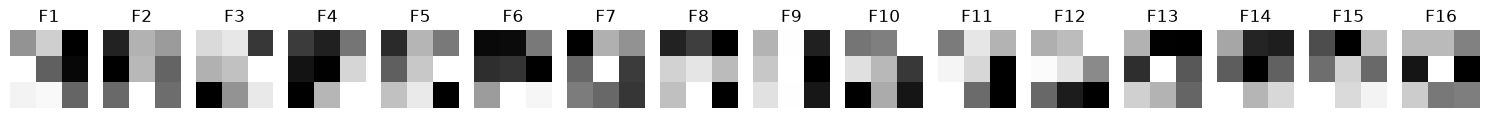

In [13]:
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,))])
train_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

model.train()
print("Starting training...")
for batch_idx, (data, target) in enumerate(train_loader):
    optimizer.zero_grad()       
    output = model(data)        
    loss = criterion(output, target) 
    loss.backward()             
    optimizer.step()            

    if batch_idx % 100 == 0:
        print(f'Batch {batch_idx}/{len(train_loader)}, Loss: {loss.item():.4f}')

print("Visualizing learned filters...")
visualize_first_layer_filters(model)
